In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report 



In [33]:
df=pd.read_csv('churn.csv')
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [34]:
df=df.drop(columns=['customerID'])

In [20]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [26]:
df['gender'].value_counts()
df['Partner'].value_counts()
df['OnlineSecurity'].value_counts()
df['DeviceProtection'].value_counts()

DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64

In [21]:
le=LabelEncoder()

In [35]:
df['gender']=le.fit_transform(df['gender'])
df['Partner']=le.fit_transform(df['Partner'])

In [36]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,1,0,0,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,1,0,0,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,1,0,0,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,0,0,0,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [37]:
df = pd.get_dummies(df, columns=["PhoneService"], dtype=int)
df = pd.get_dummies(df, columns=["MultipleLines"], dtype=int)
df = pd.get_dummies(df, columns=["InternetService"], dtype=int)
df = pd.get_dummies(df, columns=["OnlineSecurity"], dtype=int)
df = pd.get_dummies(df, columns=["OnlineBackup"], dtype=int)
df = pd.get_dummies(df, columns=["DeviceProtection"], dtype=int)

In [38]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,...,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes
0,0,0,1,No,1,No,No,No,Month-to-month,Yes,...,0,1,0,0,0,0,1,1,0,0
1,1,0,0,No,34,No,No,No,One year,No,...,0,0,0,1,1,0,0,0,0,1
2,1,0,0,No,2,No,No,No,Month-to-month,Yes,...,0,0,0,1,0,0,1,1,0,0
3,1,0,0,No,45,Yes,No,No,One year,No,...,0,0,0,1,1,0,0,0,0,1
4,0,0,0,No,2,No,No,No,Month-to-month,Yes,...,0,1,0,0,1,0,0,1,0,0


In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 31 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   gender                                7043 non-null   int32  
 1   SeniorCitizen                         7043 non-null   int64  
 2   Partner                               7043 non-null   int32  
 3   Dependents                            7043 non-null   object 
 4   tenure                                7043 non-null   int64  
 5   TechSupport                           7043 non-null   object 
 6   StreamingTV                           7043 non-null   object 
 7   StreamingMovies                       7043 non-null   object 
 8   Contract                              7043 non-null   object 
 9   PaperlessBilling                      7043 non-null   object 
 10  PaymentMethod                         7043 non-null   object 
 11  MonthlyCharges   

In [40]:
df['Dependents'].value_counts()

Dependents
No     4933
Yes    2110
Name: count, dtype: int64

In [41]:
df['Dependents']=le.fit_transform(df['Dependents'])

In [42]:
df['TechSupport'].value_counts()

TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

In [43]:
df = pd.get_dummies(df, columns=["TechSupport"], dtype=int)

In [44]:
df['StreamingTV'].value_counts()

StreamingTV
No                     2810
Yes                    2707
No internet service    1526
Name: count, dtype: int64

In [45]:
df = pd.get_dummies(df, columns=["StreamingTV"], dtype=int)

In [46]:
df['StreamingMovies'].value_counts()

StreamingMovies
No                     2785
Yes                    2732
No internet service    1526
Name: count, dtype: int64

In [47]:
df = pd.get_dummies(df, columns=["StreamingMovies"], dtype=int)

In [48]:
df['Contract'].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [49]:
df = pd.get_dummies(df, columns=["Contract"], dtype=int)

In [50]:
df['PaperlessBilling'].value_counts()

PaperlessBilling
Yes    4171
No     2872
Name: count, dtype: int64

In [51]:
df['PaperlessBilling']=le.fit_transform(df['PaperlessBilling'])

In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 39 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   gender                                7043 non-null   int32  
 1   SeniorCitizen                         7043 non-null   int64  
 2   Partner                               7043 non-null   int32  
 3   Dependents                            7043 non-null   int32  
 4   tenure                                7043 non-null   int64  
 5   PaperlessBilling                      7043 non-null   int32  
 6   PaymentMethod                         7043 non-null   object 
 7   MonthlyCharges                        7043 non-null   float64
 8   TotalCharges                          7043 non-null   object 
 9   Churn                                 7043 non-null   object 
 10  PhoneService_No                       7043 non-null   int32  
 11  PhoneService_Yes 

In [53]:
df['Churn']=le.fit_transform(df['Churn'])

In [55]:
df['PaymentMethod'].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [56]:
df = pd.get_dummies(df, columns=["PaymentMethod"], dtype=int)

In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 42 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   gender                                   7043 non-null   int32  
 1   SeniorCitizen                            7043 non-null   int64  
 2   Partner                                  7043 non-null   int32  
 3   Dependents                               7043 non-null   int32  
 4   tenure                                   7043 non-null   int64  
 5   PaperlessBilling                         7043 non-null   int32  
 6   MonthlyCharges                           7043 non-null   float64
 7   TotalCharges                             7043 non-null   object 
 8   Churn                                    7043 non-null   int32  
 9   PhoneService_No                          7043 non-null   int32  
 10  PhoneService_Yes                         7043 no

In [61]:
df[df["TotalCharges"].astype(str).str.strip().eq("") | df["TotalCharges"].isna()]


,gender,SeniorCitizen,Partner,Dependents,tenure,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,PhoneService_No,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
488,0,0,1,1,0,1,52.55,,0,1,...,1,0,0,0,0,1,1,0,0,0
753,1,0,0,1,0,0,20.25,,0,0,...,0,1,0,0,0,1,0,0,0,1
936,0,0,1,1,0,0,80.85,,0,0,...,0,0,1,0,0,1,0,0,0,1
1082,1,0,1,1,0,0,25.75,,0,0,...,0,1,0,0,0,1,0,0,0,1
1340,0,0,1,1,0,0,56.05,,0,1,...,1,0,0,0,0,1,0,1,0,0
3331,1,0,1,1,0,0,19.85,,0,0,...,0,1,0,0,0,1,0,0,0,1
3826,1,0,1,1,0,0,25.35,,0,0,...,0,1,0,0,0,1,0,0,0,1
4380,0,0,1,1,0,0,20.00,,0,0,...,0,1,0,0,0,1,0,0,0,1
5218,1,0,1,1,0,1,19.70,,0,0,...,0,1,0,0,1,0,0,0,0,1
6670,0,0,1,1,0,0,73.35,,0,0,...,1,0,0,0,0,1,0,0,0,1


In [63]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

In [64]:
df[df["TotalCharges"].astype(str).str.strip().eq("") | df["TotalCharges"].isna()]

,gender,SeniorCitizen,Partner,Dependents,tenure,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,PhoneService_No,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check


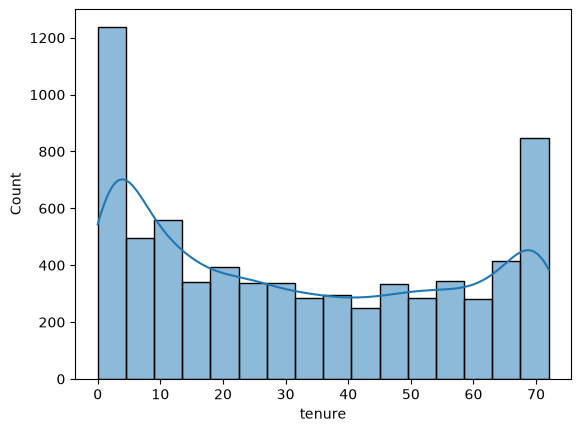

In [65]:
sns.histplot(df["tenure"], kde=True)
plt.show()

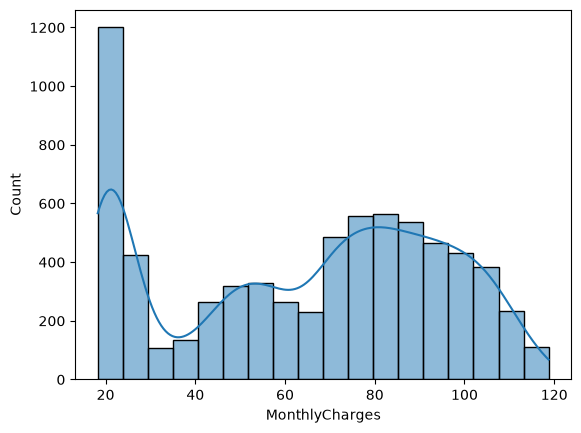

In [66]:
sns.histplot(df['MonthlyCharges'], kde=True)
plt.show()

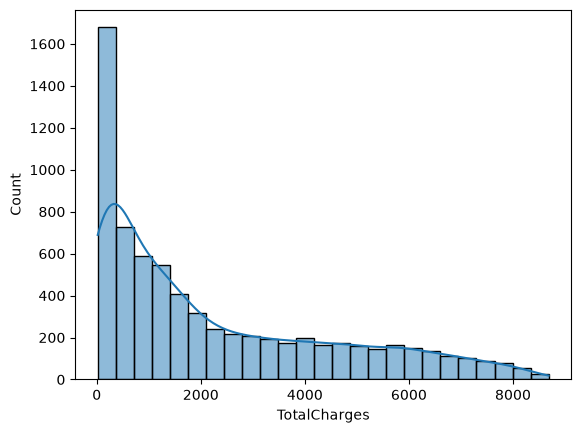

In [67]:
sns.histplot(df['TotalCharges'], kde=True)
plt.show()

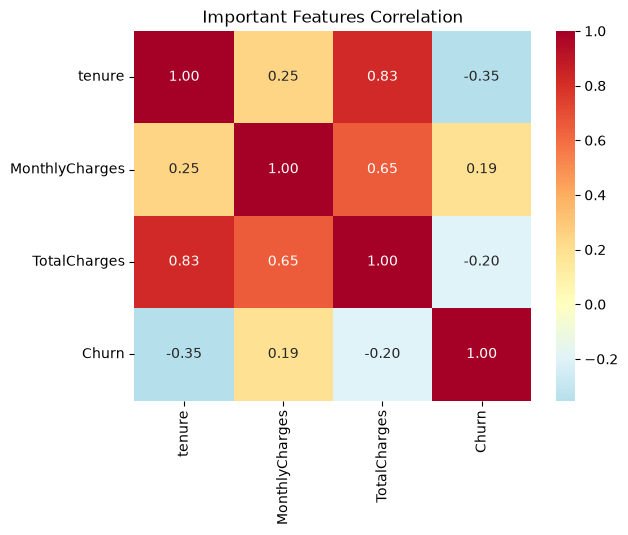

In [83]:
cols = ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]

sns.heatmap(
    df[cols].corr(),
    annot=True,
    cmap="RdYlBu_r",
    fmt=".2f",
    center=0
)

plt.title("Important Features Correlation")
plt.show()

In [68]:
scale=StandardScaler()

In [70]:
x=df.drop(columns=['Churn'])

In [71]:
y=df['Churn']

In [73]:
x_train, x_test, y_train, y_test=train_test_split(x,y ,test_size=0.2, random_state=42)

In [74]:
x_train_scale=scale.fit_transform(x_train)

In [75]:
x_test_scale=scale.fit_transform(x_test)

In [76]:
model=LogisticRegression()

In [77]:
model.fit(x_train_scale, y_train)

LogisticRegression()

In [78]:
y_predict=model.predict(x_test_scale)

In [79]:
score=accuracy_score(y_predict, y_test)

In [80]:
score

0.8204400283889283

In [85]:
confusion_matrix(y_predict, y_test)

array([[933, 150],
       [103, 223]], dtype=int64)

In [87]:
print(classification_report(y_predict, y_test))

              precision    recall  f1-score   support

           0       0.90      0.86      0.88      1083
           1       0.60      0.68      0.64       326

    accuracy                           0.82      1409
   macro avg       0.75      0.77      0.76      1409
weighted avg       0.83      0.82      0.82      1409

